# 23｜从残差块搭建小型 ResNet

## 为什么要给卷积网络留一条捷径？

第 09 课写过一个残差块：在卷积分支 $F(x)$ 之外，让输入沿捷径到达加法节点。现在我们把这种结构重复组合成一个可以训练的手写数字分类器，并和没有捷径的普通卷积网络做一组受控比较。

这是一套用于理解结构的小型网络，不是原论文中的 ResNet-18。数据使用 scikit-learn 自带的 8×8 `digits` 图像，与 28×28 MNIST 不同。网络和训练规模刻意保持较小，适合在 CPU 上运行。

**学习目标 / Outcomes**

1. 用加法和链式法则解释恒等捷径如何影响前向与反向。
2. 追踪通道、空间大小，以及尺寸改变时的投影捷径。
3. 在同一数据划分和训练规则下训练普通网络与小型残差网络，用验证集选择模型，再查看留出测试集。

In [1]:
from support import ROOT, check, show, style

In [2]:
import copy
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Circle

torch.set_num_threads(1)
style()

## 1 两条路径如何汇合

简化的残差块计算 $u=x+F(x)$。若上游梯度为 $g=\partial L/\partial u$，两条路径在输入处相加：

$$\frac{\partial L}{\partial x}=g+J_F(x)^\top g.$$

其中第一项来自恒等捷径，第二项通过卷积分支。这个等式是在**加法之后没有额外操作**的情况下写出的。如果加法之后还有 ReLU，先将上游梯度乘以该 ReLU 的局部导数，再分给两条路径；不能忽略这个激活。

下面展示本课实际使用的后激活块：分支由两层卷积组成，形状相同时捷径是恒等映射；尺寸变化时，捷径使用 1×1 卷积做投影。

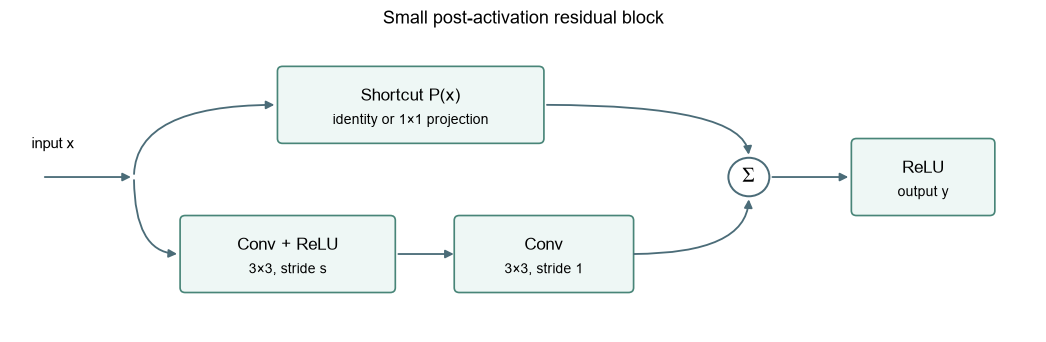

In [3]:
fig, ax = plt.subplots(figsize=(9.4, 3.0), layout='constrained')
ax.set(xlim=(0, 10), ylim=(-.1, 3)); ax.axis('off')
def node(x, y, w, title, detail):
    ax.add_patch(FancyBboxPatch((x-w/2, y-.35), w, .7, boxstyle='round,pad=.05',
                               fc='#eef7f5', ec='#488578', lw=1.1))
    ax.text(x, y+.09, title, ha='center', va='center', fontsize=11)
    ax.text(x, y-.16, detail, ha='center', va='center', fontsize=9)
def link(start, end, curve='arc3,rad=0'):
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle='-|>', mutation_scale=11,
                                 lw=1.2, color='#4b6c78', connectionstyle=curve))
node(2.7, .7, 2.0, 'Conv + ReLU', '3×3, stride s')
node(5.2, .7, 1.65, 'Conv', '3×3, stride 1')
node(3.9, 2.25, 2.5, 'Shortcut P(x)', 'identity or 1×1 projection')
ax.add_patch(Circle((7.2, 1.5), .2, fc='white', ec='#4b6c78', lw=1.3))
ax.text(7.2, 1.5, r'$\Sigma$', ha='center', va='center', fontsize=14)
node(8.9, 1.5, 1.3, 'ReLU', 'output y')
link((.3,1.5),(1.2,1.5)); link((1.2,1.5),(1.65,.7),'angle3,angleA=-90,angleB=0')
link((1.2,1.5),(2.6,2.25),'angle3,angleA=90,angleB=180')
link((3.75,.7),(4.35,.7)); link((6.05,.7),(7.2,1.3),'angle3,angleA=0,angleB=-90')
link((5.2,2.25),(7.2,1.7),'angle3,angleA=0,angleB=90'); link((7.4,1.5),(8.2,1.5))
ax.text(.2,1.8,'input x',fontsize=10); ax.set_title('Small post-activation residual block', pad=6)
show(fig)

### 练习 res01：两条梯度相加

设 $F(x)=0.5x$，加法后没有激活，来自输出的梯度为 2。计算输入梯度，保存为 `ex_gradient`。

In [4]:
ex_gradient = None

In [5]:
# 填写上一格后，运行检查。
check('input gradient', ex_gradient, 3.)

待填写：input gradient


<details>
<summary>提示</summary>

恒等路径的贡献为 2，分支路径的贡献为 $2\times0.5$。

</details>

<details>
<summary>参考答案</summary>

```python
ex_gradient = 2. * (1. + .5)
```

</details>

## 2 尺寸不同，怎样相加？

卷积特征按 `(batch, channels, height, width)` 排列。残差加法要求两路形状相同。如果卷积分支把 `(B, 8, 8, 8)` 变为 `(B, 16, 4, 4)`，就用 1×1、步长 2 的卷积同时调整捷径的通道数和空间尺寸。

空间尺寸按 $\lfloor(H+2p-k)/s\rfloor+1$ 计算：对高宽为 8 的输入，3×3 卷积取 padding=1、stride=2，得到 4。捷径的 1×1 卷积取 stride=2、padding=0，也得到 4。相加前打印两个分支的形状，便能检查该设计。

### 练习 res02：计算空间尺寸

输入高 $H=8$，卷积核 $k=3$、padding $p=1$、stride $s=2$。计算输出高并存入 `ex_height`。

In [6]:
ex_height = None

In [7]:
# 填写上一格后，运行检查。
check('output height', ex_height, 4)

待填写：output height


<details>
<summary>提示</summary>

将数值代入输出尺寸公式；向下取整。

</details>

<details>
<summary>参考答案</summary>

```python
ex_height = (8 + 2*1 - 3)//2 + 1
```

</details>

## 3 实现可切换捷径的块

下面两个模型使用相同的卷积分支。`use_skip=True` 才加上捷径；两个模型的层数、卷积宽度和训练流程相同。投影捷径会增加少量参数，因此我们还会报告参数量，比较时要把这个差别考虑进去。

In [8]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1, use_skip=True):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.use_skip = use_skip
        if use_skip:
            self.shortcut = (nn.Identity() if stride == 1 and in_channels == out_channels
                             else nn.Conv2d(in_channels, out_channels, 1, stride=stride))
        self.activation = nn.ReLU()

    def forward(self, x):
        branch = self.conv2(self.activation(self.conv1(x)))
        if self.use_skip:
            branch = branch + self.shortcut(x)
        return self.activation(branch)

class SmallImageNet(nn.Module):
    def __init__(self, use_skip=True):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(1, 8, 3, padding=1), nn.ReLU())
        self.stage1 = ConvBlock(8, 8, use_skip=use_skip)
        self.stage2 = ConvBlock(8, 16, stride=2, use_skip=use_skip)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Linear(16, 10)

    def forward(self, images):
        x = self.stem(images)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.pool(x).flatten(1)
        return self.head(x)

probe = torch.zeros(3, 1, 8, 8)
probe_model = SmallImageNet(use_skip=True)
with torch.no_grad():
    stem = probe_model.stem(probe)
    first = probe_model.stage1(stem)
    second = probe_model.stage2(first)
    scores = probe_model(probe)
print('input → stem → stage 1 → stage 2 → logits:')
print(tuple(probe.shape), tuple(stem.shape), tuple(first.shape), tuple(second.shape), tuple(scores.shape))
print('downsampling branch and shortcut:',
      tuple(probe_model.stage2.conv2(probe_model.stage2.activation(probe_model.stage2.conv1(first))).shape),
      tuple(probe_model.stage2.shortcut(first).shape))

input → stem → stage 1 → stage 2 → logits:


(3, 1, 8, 8) (3, 8, 8, 8) (3, 8, 8, 8) (3, 16, 4, 4) (3, 10)
downsampling branch and shortcut: (3, 16, 4, 4) (3, 16, 4, 4)


### 练习 res03：检查两路输出

对形状 `(3, 8, 8, 8)` 的输入，刚才的投影捷径输出是什么形状？保存为元组 `ex_shortcut_shape`。

In [9]:
ex_shortcut_shape = None

In [10]:
# 填写上一格后，运行检查。
check('shortcut shape', ex_shortcut_shape, (3, 16, 4, 4))

待填写：shortcut shape


<details>
<summary>提示</summary>

批大小不变，通道变成 16，高宽各变成 4。

</details>

<details>
<summary>参考答案</summary>

```python
ex_shortcut_shape = (3, 16, 4, 4)
```

</details>

## 4 保留独立测试集

数据像素范围是 0–16；这里除以 16 缩放到 0–1。我们按类别分层，将数据分为训练、验证、测试，比例约为 60% / 20% / 20%。训练集更新权重；每轮验证集用于保存该模型的最低验证损失；随后通过验证损失在两个模型之间选择，最后只报告选定模型的测试结果。

普通网络与残差网络共享数据、batch 大小、训练轮数、优化器、学习率及打乱顺序；它们的参数量和计算路径不同。这个小实验帮助观察结果，不保证残差网络在任何设置下都更好。

In [11]:
digits = load_digits()
images = torch.tensor(digits.images[:, None] / 16., dtype=torch.float32)
labels = torch.tensor(digits.target, dtype=torch.long)
indices = np.arange(len(labels))
train_ids, rest_ids = train_test_split(indices, test_size=.4, random_state=23, stratify=digits.target)
val_ids, test_ids = train_test_split(rest_ids, test_size=.5, random_state=23, stratify=digits.target[rest_ids])
print('train / validation / test:', len(train_ids), len(val_ids), len(test_ids))
print('input shape:', tuple(images.shape), 'label shape:', tuple(labels.shape))

train / validation / test: 1078 359 360
input shape: (1797, 1, 8, 8) label shape: (1797,)


### 练习 res04：识别评价职责

若要在普通网络和残差网络中选一个，应比较哪个集合的损失？将字符串 `"train"`、`"validation"` 或 `"test"` 存入 `ex_selection_set`。

In [12]:
ex_selection_set = None

In [13]:
# 填写上一格后，运行检查。
check('selection set', ex_selection_set, 'validation')

待填写：selection set


<details>
<summary>提示</summary>

保留测试集，模型选择使用验证集。

</details>

<details>
<summary>参考答案</summary>

```python
ex_selection_set = 'validation'
```

</details>

## 5 训练并比较验证曲线

每一轮先训练，再以 `model.eval()` 计算验证交叉熵和准确率；验证阶段关闭梯度。按验证交叉熵保存每个模型最好的权重。两个模型使用同一个随机种子创建训练顺序，这使每轮样本顺序一致；结构和捷径参数的不同仍会影响初始化与优化。

In [14]:
def fit_model(use_skip, seed=23, epochs=10):
    torch.manual_seed(seed)
    model = SmallImageNet(use_skip=use_skip)
    generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(TensorDataset(images[train_ids], labels[train_ids]),
                              batch_size=64, shuffle=True, generator=generator)
    optimizer = torch.optim.Adam(model.parameters(), lr=.003)
    criterion = nn.CrossEntropyLoss()
    history = []
    best_state, best_loss = None, float('inf')
    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            loss = criterion(model(xb), yb)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            logits = model(images[val_ids])
            val_loss = criterion(logits, labels[val_ids]).item()
            val_acc = (logits.argmax(dim=1) == labels[val_ids]).float().mean().item()
        history.append((val_loss, val_acc))
        if val_loss < best_loss:
            best_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return model, np.array(history), best_loss

runs = {}
for name, use_skip in [('Plain CNN', False), ('Residual CNN', True)]:
    model, history, best = fit_model(use_skip)
    runs[name] = (model, history, best)
    print(f'{name}: parameters={sum(p.numel() for p in model.parameters())}, best validation CE={best:.4f}')
selected_name = min(runs, key=lambda name: runs[name][2])
selected_model = runs[selected_name][0]
print('selected by validation CE:', selected_name)

Plain CNN: parameters=4906, best validation CE=0.9447


Residual CNN: parameters=5050, best validation CE=0.7533
selected by validation CE: Residual CNN


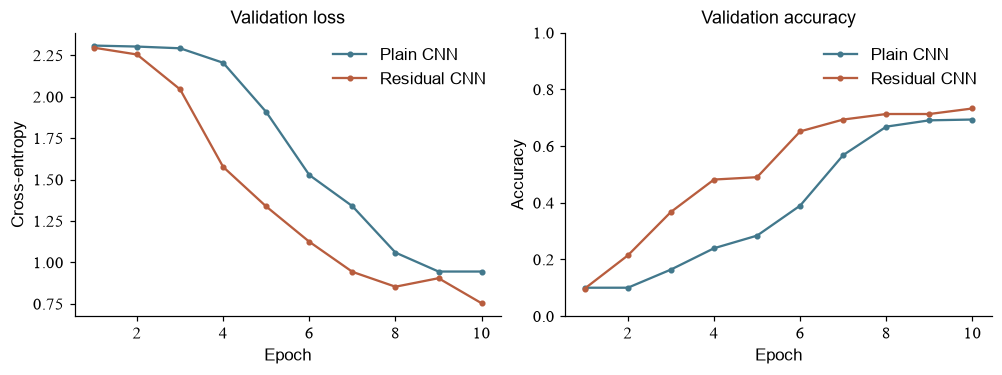

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3), layout='constrained')
for (name, (_, history, _)), color in zip(runs.items(), ['#42788c', '#b85d3e']):
    epochs = np.arange(1, len(history)+1)
    axes[0].plot(epochs, history[:, 0], marker='.', color=color, label=name)
    axes[1].plot(epochs, history[:, 1], marker='.', color=color, label=name)
axes[0].set(xlabel='Epoch', ylabel='Cross-entropy', title='Validation loss')
axes[1].set(xlabel='Epoch', ylabel='Accuracy', title='Validation accuracy', ylim=(0, 1))
for ax in axes: ax.legend(frameon=False)
show(fig)

同一轮对应一组参数，图上两条曲线分别来自普通和残差网络；两种网络的参数量可能不同。验证损失和准确率衡量不同方面，可以出现方向不完全一致的情况。本次用预先指定的验证损失选模型与轮次。

### 练习 res05：根据验证损失选择

两个配置的验证交叉熵为 `plain=0.6`、`residual=0.4`。按最低验证损失选择，将字符串 `"plain"` 或 `"residual"` 保存为 `ex_best`。

In [16]:
ex_best = None

In [17]:
# 填写上一格后，运行检查。
check('validation selection', ex_best, 'residual')

待填写：validation selection


<details>
<summary>提示</summary>

交叉熵越小越好。

</details>

<details>
<summary>参考答案</summary>

```python
ex_best = 'residual'
```

</details>

## 6 固定选择，检查测试集与错例

混淆矩阵的行是真实数字，列是预测数字。查看第一张错图及其真实类别与预测类别，判断模型可能混淆了哪些笔画。

selected test accuracy: 0.6917


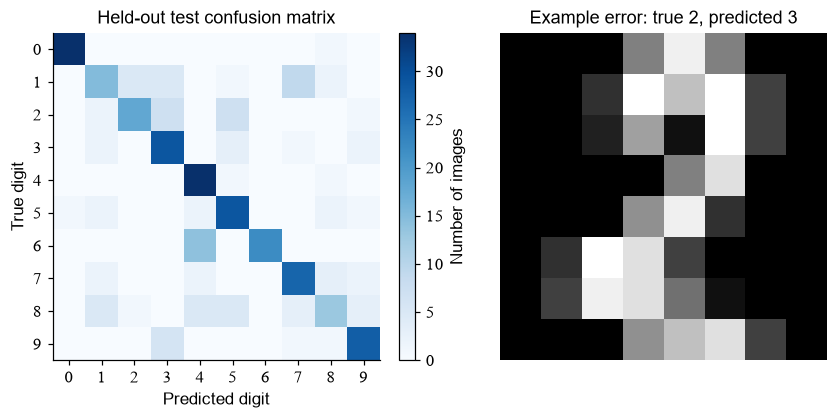

In [18]:
selected_model.eval()
with torch.no_grad():
    test_logits = selected_model(images[test_ids])
    test_pred = test_logits.argmax(dim=1).numpy()
test_y = labels[test_ids].numpy()
print('selected test accuracy:', round(float(np.mean(test_pred == test_y)), 4))
cm = confusion_matrix(test_y, test_pred, labels=np.arange(10))
wrong = np.flatnonzero(test_pred != test_y)
fig, axes = plt.subplots(1, 2, figsize=(8, 3.7), layout='constrained')
im = axes[0].imshow(cm, cmap='Blues')
axes[0].set(xlabel='Predicted digit', ylabel='True digit', title='Held-out test confusion matrix',
            xticks=range(10), yticks=range(10))
fig.colorbar(im, ax=axes[0], label='Number of images')
if len(wrong):
    i = wrong[0]
    axes[1].imshow(images[test_ids[i], 0], cmap='gray', vmin=0, vmax=1)
    axes[1].set_title(f'Example error: true {test_y[i]}, predicted {test_pred[i]}')
else:
    axes[1].text(.5, .5, 'No errors in this run', ha='center', va='center')
axes[1].axis('off')
show(fig)

## 7 继续实验与阅读

1. 在固定数据划分和训练预算下，以多个随机种子重复完整实验，记录参数量、验证损失与曲线。不要根据测试集反复挑选设置。
2. 在验证集上比较将相加后的 ReLU 移除或保留，对照第 1 节的梯度公式；保持其余代码一致。
3. 查看 [Deep Residual Learning for Image Recognition](https://arxiv.org/abs/1512.03385) 中的 basic block，指出本课小网络与论文网络的层数、归一化和训练任务的区别。

当迁移到 MNIST 时，输入从 8×8 变为 28×28；先画出一张图，再追踪每层尺寸和训练成本。第 20 课提供可选的 MNIST 下载与数据划分示例。